In [118]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import tensorflow.keras as keras
from sklearn.preprocessing import StandardScaler
import time
from scipy import stats

from pathlib import Path

# --- ONE set of path definitions, pointing at Drive ---
DATA_DIR = Path("/content/drive/MyDrive/AMEX1B - Data ")  # trailing space is part of the real folder name
CSV_DIR = DATA_DIR / "csv_files"
CACHE_DIR = DATA_DIR / "cache"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [119]:
#SQUASHING FROM GITHUB (James)
def main():
    # Start the processing timer.
    process_start = time.perf_counter()

    train_dataset = load_or_build_dataset("train")
    test_dataset = load_or_build_dataset("test")

    print(f"Train Dataset Shape: {train_dataset.shape}\n")
    print(f"Test Dataset Shape: {test_dataset.shape}\n")

    # Stopping hte processing timer.
    process_end = time.perf_counter()
    elapsed_time = process_end - process_start

    print(f"Elapsed time: {elapsed_time} seconds\n")

def get_cache_path(split: str) -> Path:
    return CACHE_DIR / f"{split}_master.parquet"

def load_or_build_dataset(split: str, force_rebuild: bool = False) -> pd.DataFrame:
    cache_path = get_cache_path(split)

    if cache_path.exists() and not force_rebuild:
        print(f"Loading {split} from cache: {cache_path}")

        return pd.read_parquet(cache_path)

    print(f"Building {split} from raw CSVs if no cache found or force_rebuild=True...")

    df = build_base_dataset(split)

    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    df.to_parquet(cache_path, index=False)
    print(f"Cached {split} to: {cache_path}")

    return df

# Load, validate and merge the base table with the depth 0 tables.
def build_base_dataset(split: str) -> pd.DataFrame:
    print(f"Building the base dataset for {split}...\n")

    # Load, validate base table.
    base = load_base(split)
    validate_depth0_table(base, "base")
    print("Loaded base table.\n")

    # Load, validate, merge base with static0 table.
    static_0 = load_static_0(split)
    validate_depth0_table(static_0, "static_0")
    merged = join_static_0(base, static_0)
    print("Merged static_0 into base table.\n")

    # Load, validate, merge base with static cb 0 table.
    static_cb_0 = load_static_cb_0(split)
    validate_depth0_table(static_cb_0, "static_cb_0")
    merged = join_static_cb_0(merged, static_cb_0)
    print("Merged static_cb_0 into base table.\n")

    # Load, aggregate, merge tax_registry_a_1 table.
    tax_registry_a_1 = load_tax_registry_a_1(split)
    tax_registry_agg = aggregate_tax_registry_a_1(tax_registry_a_1)
    merged = join_tax_registry_a_1(merged, tax_registry_agg)
    print("Merged tax_registry_a_1 into base table.\n")

    # Load, aggregate, merge person_1 table.
    person_1 = load_person_1(split)
    person_agg = aggregate_person_1(person_1)
    merged = join_person_1(merged, person_agg)
    print("Merged person_1 into base table.\n")

    # Load, aggregate, merge applprev_1 table.
    applprev_1 = load_applprev_1(split)
    applprev_agg = aggregate_applprev_1(applprev_1)
    merged = join_applprev_1(merged, applprev_agg)
    print("Merged applprev_1 into base table.\n")

    # Load, aggregate, merge credit_bureau_a_1 table.
    credit_bureau_a_1 = load_credit_bureau_a_1(split)
    bureau_agg = aggregate_credit_bureau_a_1(credit_bureau_a_1)
    merged = join_credit_bureau_a_1(merged, bureau_agg)
    print("Merged credit_bureau_a_1 into base table.\n")

    # Thin-file flag with zero rows in the raw (pre-aggregation) bureau table.
    merged["is_thin_file"] = build_thin_file_flag(base, credit_bureau_a_1)
    # Make sure the thin-file flag column actually exists and has the
    # expected boolean values before moving on.
    print(f"Thin-file flag: {merged['is_thin_file']}.\n")

    # Load, aggregate (two parts with subrecord to contract to case), merge
    # credit_bureau_a_2 table.
    credit_bureau_a_2 = load_credit_bureau_a_2(split)
    contract_agg = aggregate_credit_bureau_a_2_to_contract(credit_bureau_a_2)
    bureau_a2_case_agg = aggregate_credit_bureau_a_2_to_case(contract_agg)
    merged = join_credit_bureau_a_2(merged, bureau_a2_case_agg)
    print("Merged credit_bureau_a2_contract_case_agg into base table.\n")

    print(f"Finished building the base dataset for {split}!\n")

    return merged

# Returns the split directory which should
# be either split = "train" or "test".
#   get_split_dir("train")
def get_split_dir(split: str) -> Path:
    return CSV_DIR / split

# Load the base table, one row per loan, for
# the given split.
#   load_base("test")
def load_base(split: str) -> pd.DataFrame:
    path = get_split_dir(split) / f"{split}_base.csv"

    return pd.read_csv(path)

# Sum a group but return NaN, not 0, if every value in the
# group is NaN. Prevents "no records" from looking identical
# to "records summed to zero".
def sum_min_count(x: pd.Series):
    return x.sum(min_count=1)

# Load and concatenate the static_0 table, which are
# split into two files.
#   load_static_0("train")
def load_static_0(split: str) -> pd.DataFrame:
    split_dir = get_split_dir(split)

    part_0 = pd.read_csv(split_dir / f"{split}_static_0_0.csv")
    part_1 = pd.read_csv(split_dir / f"{split}_static_0_1.csv")

    # The ignore index parameter is needed because without it the
    # concantenated DF will keep each part's original row index,
    # meaning possible duplicate index 0 for example. Using it
    # re-numbers the index starting from 0 onward.
    return pd.concat([part_0, part_1], ignore_index=True)

# Validate the depth 0 tables to make sure there are no duplicate IDs.
#   validate_depth0_table(train_base, "base")
def validate_depth0_table(df: pd.DataFrame, name: str) -> None:
    dupes = df["case_id"].duplicated().sum()

    if dupes > 0:
        raise ValueError(f"{name}: found {dupes} duplicate case_id values")

    print(f"{name}: {len(df)} rows, no duplicate case_id, all is good!")

# Join the static 0 table with the base table on case ID.
# This is present only for about 70% of applicants.
#   join_static_0(test_base, test_static_0)
def join_static_0(base: pd.DataFrame, static_0: pd.DataFrame) -> pd.DataFrame:
    # Use Left Outer Join in order to use all keys from the left dataframe
    # and missing matches from the right dataframe are filled with NaN.
    # The one to one validation checks that the join keys are unique on
    # both sides and notifies immediately if, for example, a duplicate
    # case_id snuck in.
    merged = base.merge(static_0, on="case_id", how="left", validate="one_to_one")

    # This is a row count check after merging just in case
    # duplicate keys slipped through the cracks.
    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

# Join the static cb 0 table with the base table on case ID.
# About 30% of the rows will get NaN because these are the thin-file
# people with no history.
#   join_static_cb_0(train_static_cb_0, train_static_cb_0)
def join_static_cb_0(base: pd.DataFrame, static_cb_0: pd.DataFrame) -> pd.DataFrame:
    # Use Left Outer Join in order to use all keys from the left dataframe
    # and missing matches from the right dataframe are filled with NaN.
    merged = base.merge(static_cb_0, on="case_id", how="left", validate="one_to_one")

    # This is a row count check after merging just in case
    # duplicate keys slipped through the cracks.
    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

# Load the static cb 0 table.
#   load_static_cb_0("train")
def load_static_cb_0(split: str) -> pd.DataFrame:
    path = get_split_dir(split) / f"{split}_static_cb_0.csv"

    return pd.read_csv(path)

# Load the tax_registry_a_1 table.
# Depth 1, meaning many rows per case_id.
#   load_tax_registry_a_1("train")
def load_tax_registry_a_1(split: str) -> pd.DataFrame:
    path = get_split_dir(split) / f"{split}_tax_registry_a_1.csv"

    return pd.read_csv(path)

# Aggregate tax_registry_a_1 to one row per case_id.
#   aggregate_tax_registry_a_1(train_tax_registry_a_1)
def aggregate_tax_registry_a_1(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.groupby("case_id")
        .agg(
            tax_record_count=("num_group1", "count"),
            tax_amount_sum=("amount_4527230A", sum_min_count),
            tax_amount_mean=("amount_4527230A", "mean"),
            tax_amount_max=("amount_4527230A", "max"),
        )
        .reset_index()
    )

# Join the aggregated tax_registry_a_1 onto the merged base table.
#   join_tax_registry_a_1(merged, tax_registry_agg)
def join_tax_registry_a_1(base: pd.DataFrame, tax_registry_agg: pd.DataFrame) -> pd.DataFrame:
    merged = base.merge(tax_registry_agg, on="case_id", how="left", validate="one_to_one")

    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

# Load the person_1 table.
# Depth 1, meaning 1 to 2 rows per case_id with applicant + optional co-applicant.
#   load_person_1("train")
def load_person_1(split: str) -> pd.DataFrame:
    path = get_split_dir(split) / f"{split}_person_1.csv"

    return pd.read_csv(path)

# Aggregate person_1 to one row per case_id.
#   aggregate_person_1(train_person_1)
def aggregate_person_1(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.groupby("case_id")
        .agg(
            person_count=("num_group1", "count"),
            person_income_sum=("mainoccupationinc_384A", sum_min_count),
            person_income_mean=("mainoccupationinc_384A", "mean"),
            person_income_max=("mainoccupationinc_384A", "max"),
            employment_mean=("empl_employedtotal_800L", "mean"),
            employment_max=("empl_employedtotal_800L", "max")
        )
        .reset_index()
    )

# Join the aggregated person_1 onto the merged base table.
#   join_person_1(merged, person_agg)
def join_person_1(base: pd.DataFrame, person_agg: pd.DataFrame) -> pd.DataFrame:
    merged = base.merge(person_agg, on="case_id", how="left", validate="one_to_one")

    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

# Load the applprev_1 table.
# Depth 1, meaning 0 to4 rows per case_id for the applicant's
# own previous applications to this lender.
#   load_applprev_1("train")
def load_applprev_1(split: str) -> pd.DataFrame:
    path = get_split_dir(split) / f"{split}_applprev_1.csv"

    return pd.read_csv(path)

# Aggregate applprev_1 to one row per case_id.
#   aggregate_applprev_1(train_applprev_1)
def aggregate_applprev_1(df: pd.DataFrame) -> pd.DataFrame:
    # Make a copy so as to not mutate the original DataFrame.
    df = df.copy()
    # Conver the string dates to real datetimes so our min/max will
    # sort chronologically and not alphabetically.
    # Any value that cannot be parsed will become NaT, Not a Time,
    # instead of crashing.
    df["approvaldate_319D"] = pd.to_datetime(df["approvaldate_319D"], errors="coerce")

    return (
        df.groupby("case_id")
        .agg(
            prev_application_count=("num_group1", "count"),
            prev_credit_amount_sum=("credamount_590A", sum_min_count),
            prev_credit_amount_mean=("credamount_590A", "mean"),
            prev_credit_amount_max=("credamount_590A", "max"),
            prev_approval_date_min=("approvaldate_319D", "min"),
            prev_approval_date_max=("approvaldate_319D", "max"),
        )
        .reset_index()
    )

# Join the aggregated applprev_1 onto the merged base table.
#   join_applprev_1(merged, applprev_agg)
def join_applprev_1(base: pd.DataFrame, applprev_agg: pd.DataFrame) -> pd.DataFrame:
    merged = base.merge(applprev_agg, on="case_id", how="left", validate="one_to_one")

    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

# Load and concatenate the credit_bureau_a_1 table, split into two files.
# This is the most important signal table where the thin-file applicants
# have zero rows in.
#   load_credit_bureau_a_1("train")
def load_credit_bureau_a_1(split: str) -> pd.DataFrame:
    split_dir = get_split_dir(split)

    part_0 = pd.read_csv(split_dir / f"{split}_credit_bureau_a_1_0.csv")
    part_1 = pd.read_csv(split_dir / f"{split}_credit_bureau_a_1_1.csv")

    return pd.concat([part_0, part_1], ignore_index=True)

# Aggregate credit_bureau_a_1 to one row per case_id.
#   aggregate_credit_bureau_a_1(train_credit_bureau_a_1)
def aggregate_credit_bureau_a_1(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.groupby("case_id")
        .agg(
            bureau_contract_count=("num_group1", "count"),
            bureau_credit_amount_sum=("credamount_770A", sum_min_count),
            bureau_credit_amount_mean=("credamount_770A", "mean"),
            bureau_credit_amount_max=("credamount_770A", "max"),
            bureau_overdue_amount_mean=("overdueamountmax_950A", "mean"),
            bureau_overdue_amount_max=("overdueamountmax_950A", "max"),
            bureau_dpd_max=("pmts_dpdvalue_108P", "max"),
            bureau_dpd_mean=("pmts_dpdvalue_108P", "mean"),
        )
        .reset_index()
    )

# Helper to compute the thin-file flag.
# True if this case_id has zero rows in the raw pre-aggregation credit_bureau_a_1 table,
# meaning no bureau history at all.
#   build_thin_file_flag(train_base, train_credit_bureau_a_1)
def build_thin_file_flag(base: pd.DataFrame, credit_bureau_a_1: pd.DataFrame) -> pd.Series:
    has_bureau = base["case_id"].isin(credit_bureau_a_1["case_id"])

    is_thin_file = has_bureau == False

    return is_thin_file

# Join the aggregated credit_bureau_a_1 onto the merged base table.
#   join_credit_bureau_a_1(merged, bureau_agg)
def join_credit_bureau_a_1(base: pd.DataFrame, bureau_agg: pd.DataFrame) -> pd.DataFrame:
    merged = base.merge(bureau_agg, on="case_id", how="left", validate="one_to_one")

    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

# Load the credit_bureau_a_2 table.
# Depth 2, meaning case_id to num_group1 (contract) to
# num_group2 (payment/subrecord within that contract) which is the largest table.
#   load_credit_bureau_a_2("train")
def load_credit_bureau_a_2(split: str) -> pd.DataFrame:
    path = get_split_dir(split) / f"{split}_credit_bureau_a_2.csv"

    return pd.read_csv(path)

# Part 1: Collapse credit_bureau_a_2 from subrecord level (case_id, num_group1, num_group2) to
# contract level (case_id, num_group1). One row per past credit
# contract by summarizing its payment history.
#   aggregate_credit_bureau_a_2_to_contract(train_credit_bureau_a_2)
def aggregate_credit_bureau_a_2_to_contract(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.groupby(["case_id", "num_group1"])
        .agg(
            contract_subrecord_count=("num_group2", "count"),
            contract_overdue_sum=("pmts_overdue_1140A", sum_min_count),
            contract_overdue_max=("pmts_overdue_1140A", "max"),
            contract_overdue_valid_count=("pmts_overdue_1140A", "count"),
        )
        .reset_index()
    )

# Part 2: Collapse contract-level credit_bureau_a_2 summaries from (case_id, num_group1)
# to one row per case_id.
#   aggregate_credit_bureau_a_2_to_case(contract_agg)
def aggregate_credit_bureau_a_2_to_case(contract_agg: pd.DataFrame) -> pd.DataFrame:
    case_agg = (
        contract_agg.groupby("case_id")
        .agg(
            bureau_a2_contract_count=("num_group1", "count"),
            bureau_a2_record_count=("contract_subrecord_count", "sum"),
            bureau_a2_overdue_sum=("contract_overdue_sum", sum_min_count),
            bureau_a2_overdue_max=("contract_overdue_max", "max"),
            bureau_a2_overdue_valid_count=("contract_overdue_valid_count", "sum"),
        )
        .reset_index()
    )

    # Weighted mean, computed after. aggregation. This is the total overdue divided by
    # total valid records and not the average of each contract's own mean.
    # This avoids overweighting contracts that happen to have fewer subrecords.
    case_agg["bureau_a2_overdue_mean"] = (
        case_agg["bureau_a2_overdue_sum"] / case_agg["bureau_a2_overdue_valid_count"]
    )

    return case_agg

# Join both aggregated credit_bureau_a_2 parts into the merged base table.
#   join_credit_bureau_a_2(merged, bureau_a2_case_agg)
def join_credit_bureau_a_2(base: pd.DataFrame, bureau_a2_case_agg: pd.DataFrame) -> pd.DataFrame:
    merged = base.merge(bureau_a2_case_agg, on="case_id", how="left", validate="one_to_one")

    if len(merged) != len(base):
        raise ValueError(
            f"Row count changed after join: base had {len(base)}, "
            f"merged has {len(merged)}"
        )

    return merged

if __name__ == "__main__":
    main()

Loading train from cache: /content/drive/MyDrive/AMEX1B - Data /cache/train_master.parquet
Loading test from cache: /content/drive/MyDrive/AMEX1B - Data /cache/test_master.parquet
Train Dataset Shape: (1000000, 46)

Test Dataset Shape: (200000, 45)

Elapsed time: 1.9889726549999978 seconds



In [120]:
df_train_master = pd.read_parquet(CACHE_DIR / "train_master.parquet")
df_train_master.shape

(1000000, 46)

In [121]:
df_train_master.columns.tolist()

['case_id',
 'date_decision',
 'MONTH',
 'WEEK_NUM',
 'target',
 'mainoccupationinc_384A',
 'credamount_770A',
 'annuity_780A',
 'days_employed_700P',
 'education_927M',
 'maritalstatus_703M',
 'birth_259D',
 'riskassesment_940T',
 'numberofqueries_146L',
 'description_5085714M',
 'tax_record_count',
 'tax_amount_sum',
 'tax_amount_mean',
 'tax_amount_max',
 'person_count',
 'person_income_sum',
 'person_income_mean',
 'person_income_max',
 'employment_mean',
 'employment_max',
 'prev_application_count',
 'prev_credit_amount_sum',
 'prev_credit_amount_mean',
 'prev_credit_amount_max',
 'prev_approval_date_min',
 'prev_approval_date_max',
 'bureau_contract_count',
 'bureau_credit_amount_sum',
 'bureau_credit_amount_mean',
 'bureau_credit_amount_max',
 'bureau_overdue_amount_mean',
 'bureau_overdue_amount_max',
 'bureau_dpd_max',
 'bureau_dpd_mean',
 'is_thin_file',
 'bureau_a2_contract_count',
 'bureau_a2_record_count',
 'bureau_a2_overdue_sum',
 'bureau_a2_overdue_max',
 'bureau_a2_ove

In [122]:
#View spread of data and quality
import pandas as pd

print("MISSING VALUES")
# calculate count and percentage of missing values
missing_df = pd.DataFrame({
    'Missing Count': df_train_master.isna().sum(),
    'Missing %': (df_train_master.isna().mean() * 100).round(2)
})
display(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing %', ascending=False))

print("DATA TYPES")
# show data types to spot incorrect ones (like numeric data stored as objects)
display(df_train_master.dtypes.value_counts())
display(df_train_master.dtypes)

print("SPREAD OF DATA")
# generate min, max, mean, and quartiles to understand spread
display(df_train_master.describe().T)

print("INCORRECT VALUES")
# check for invalid data
invalid_checks = {
    "Negative Age": (df_train_master.get('age', pd.Series(dtype=float)) < 0).sum(),
    "Age > 120 (Unrealistic)": (df_train_master.get('age', pd.Series(dtype=float)) > 120).sum(),
    "Negative Income (Main)": (df_train_master.get('mainoccupationinc_384A', pd.Series(dtype=float)) < 0).sum(),
    "Negative Credit Amount": (df_train_master.get('credamount_770A', pd.Series(dtype=float)) < 0).sum(),
    "Negative Annuity": (df_train_master.get('annuity_780A', pd.Series(dtype=float)) < 0).sum(),
    "Negative Days Employed": (df_train_master.get('days_employed_700P', pd.Series(dtype=float)) < 0).sum()
}

for check_name, count in invalid_checks.items():
    if count > 0:
        print(f"{check_name}: {count} rows found")
    else:
        print(f"{check_name}: 0 rows found (Clean)")

MISSING VALUES


,Missing Count,Missing %
bureau_a2_overdue_max,359745,35.97
bureau_a2_overdue_mean,359745,35.97
bureau_a2_overdue_sum,359745,35.97
bureau_overdue_amount_mean,337107,33.71
bureau_overdue_amount_max,337107,33.71
riskassesment_940T,334965,33.50
bureau_a2_record_count,329111,32.91
bureau_a2_overdue_valid_count,329111,32.91
bureau_a2_contract_count,329111,32.91
numberofqueries_146L,299821,29.98


DATA TYPES


,count
float64,33
int64,5
object,5
datetime64[ns],2
bool,1


,0
case_id,int64
date_decision,object
MONTH,int64
WEEK_NUM,int64
target,int64
mainoccupationinc_384A,float64
credamount_770A,float64
annuity_780A,float64
days_employed_700P,float64
education_927M,object


SPREAD OF DATA


,count,mean,min,25%,50%,75%,max,std
case_id,1000000.0,500000.5,1.0,250000.75,500000.5,750000.25,1000000.0,288675.278933
MONTH,1000000.0,201948.289559,201901.0,201906.0,201911.0,202004.0,202009.0,48.800468
WEEK_NUM,1000000.0,45.498973,0.0,23.0,45.0,68.0,91.0,26.560375
target,1000000.0,0.191752,0.0,0.0,0.0,0.0,1.0,0.393679
mainoccupationinc_384A,950349.0,24477.415393,2515.0,16139.0,22021.0,30008.0,174473.0,11911.971994
credamount_770A,980041.0,16730.809971,1447.0,10527.0,14760.0,20693.0,150395.0,8932.87458
annuity_780A,900323.0,1242.750132,79.0,782.0,1097.0,1538.0,12069.0,661.880406
days_employed_700P,849429.0,1524.346248,0.0,861.0,1502.0,2141.0,5852.0,902.202133
riskassesment_940T,665035.0,0.49977,0.0102,0.3373,0.4996,0.6624,0.9939,0.208339
numberofqueries_146L,700179.0,2.997915,0.0,2.0,3.0,4.0,18.0,1.998898


INCORRECT VALUES
Negative Age: 0 rows found (Clean)
Age > 120 (Unrealistic): 0 rows found (Clean)
Negative Income (Main): 0 rows found (Clean)
Negative Credit Amount: 0 rows found (Clean)
Negative Annuity: 0 rows found (Clean)
Negative Days Employed: 0 rows found (Clean)


In [123]:
# CLEANING & FORMATTING

# Converting date columns from object to date time format
date_cols = ["date_decision", "birth_259D", "prev_approval_date_min", "prev_approval_date_max"]
for col in date_cols:
  if col in df_train_master.columns:
    df_train_master[col] = pd.to_datetime(df_train_master[col], errors='coerce')

# Printing out updated date type counts
print("Data types: ")
display(df_train_master.dtypes.value_counts())
display(df_train_master.dtypes)

# formatting categorical strings and rows that contain text labels
categorical_cols = df_train_master.select_dtypes(include=['object', 'category']).columns.tolist()
for col in categorical_cols:
  valid_text_labels = df_train_master[col].notna()

  # lowercase, trimming spaces, and changing spaces between words to hyphens (' ') -> ('-')
  df_train_master.loc[valid_text_labels, col] = (df_train_master.loc[valid_text_labels, col].astype(str).str.lower().str.strip().str.replace(r'\s+', '-', regex=True))

  # replacing text words in unknown values list with nan, keeping NA's for now to train the model and see how it works and then deciding later based on results
  unknown_values = ['nan', 'none', 'null', '', 'unknown', 'missing', 'missing_value']
  df_train_master[col] = df_train_master[col].replace(unknown_values, np.nan)
print(f"Formatted and Clean categorical columns: {len(categorical_cols)}")

# printing out missing values
display(df_train_master[categorical_cols].isna().sum().to_frame(name = "missing values count"))

Data types: 


,count
float64,33
int64,5
datetime64[ns],4
object,3
bool,1


,0
case_id,int64
date_decision,datetime64[ns]
MONTH,int64
WEEK_NUM,int64
target,int64
mainoccupationinc_384A,float64
credamount_770A,float64
annuity_780A,float64
days_employed_700P,float64
education_927M,object


Formatted and Clean categorical columns: 3


,missing values count
education_927M,0
maritalstatus_703M,0
description_5085714M,299821


In [124]:
# Feature Engineering STEP 1: IDENTIFY FEATURE TYPES AND TARGET

# Identify ID and target columns
id_col = "case_id"
target_col = "target"

print("Number of rows:", df_train_master.shape[0])
print("Number of columns:", df_train_master.shape[1])

print("\nID column:", id_col)
print("Target column:", target_col)
print("0 = repaid")
print("1 = default")

Number of rows: 1000000
Number of columns: 46

ID column: case_id
Target column: target
0 = repaid
1 = default


In [125]:
# Identify feature types
numeric_cols = df_train_master.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = df_train_master.select_dtypes(include=["object", "category"]).columns.tolist()

date_cols = df_train_master.select_dtypes(include=["datetime64[ns]"]).columns.tolist()

boolean_cols = df_train_master.select_dtypes(include=["bool"]).columns.tolist()

# case_id and target are numeric columns,
# but they are not numerical predictor features
numeric_features = [
    col for col in numeric_cols
    if col not in [id_col, target_col]
]

print("\nNumeric features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_cols))
print(categorical_cols)

print("\nDate features:", len(date_cols))
print(date_cols)

print("\nBoolean features:", len(boolean_cols))
print(boolean_cols)


Numeric features: 36
['MONTH', 'WEEK_NUM', 'mainoccupationinc_384A', 'credamount_770A', 'annuity_780A', 'days_employed_700P', 'riskassesment_940T', 'numberofqueries_146L', 'tax_record_count', 'tax_amount_sum', 'tax_amount_mean', 'tax_amount_max', 'person_count', 'person_income_sum', 'person_income_mean', 'person_income_max', 'employment_mean', 'employment_max', 'prev_application_count', 'prev_credit_amount_sum', 'prev_credit_amount_mean', 'prev_credit_amount_max', 'bureau_contract_count', 'bureau_credit_amount_sum', 'bureau_credit_amount_mean', 'bureau_credit_amount_max', 'bureau_overdue_amount_mean', 'bureau_overdue_amount_max', 'bureau_dpd_max', 'bureau_dpd_mean', 'bureau_a2_contract_count', 'bureau_a2_record_count', 'bureau_a2_overdue_sum', 'bureau_a2_overdue_max', 'bureau_a2_overdue_valid_count', 'bureau_a2_overdue_mean']

Categorical features: 3
['education_927M', 'maritalstatus_703M', 'description_5085714M']

Date features: 4
['date_decision', 'birth_259D', 'prev_approval_date_m

In [126]:
# Examine target distribution
target_counts = df_train_master[target_col].value_counts().sort_index()
target_percentages = ( df_train_master[target_col].value_counts(normalize=True).sort_index().mul(100))

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

print("\nTARGET DISTRIBUTION")
display(target_summary)


TARGET DISTRIBUTION


,Count,Percentage
target,,
0,808248,80.8248
1,191752,19.1752


The target variable is imbalanced. Roughly 81% repaid vs. 19% default.

In [127]:
# Step 2: Seperate X and y
# X contains all the columns except for target
# y only contains the target column

target_col = "target"
id_col = "case_id"

y = df_train_master[target_col]
X = df_train_master.drop(columns=[target_col])

In [128]:
#Step 3: Split into train/validation using WEEK_NUM

#Look at the column
print(X["WEEK_NUM"].min(), X["WEEK_NUM"].max())
print(X["WEEK_NUM"].value_counts().sort_index())

0 91
WEEK_NUM
0     10769
1     10722
2     10804
3     10980
4     11049
      ...  
87    10973
88    10844
89    11037
90    10880
91    10940
Name: count, Length: 92, dtype: int64


Train set runs weeks 0–91

We chose Week 80 as the cutoff because it allows us to use Weeks 0–79 for training while saving the last 12 weeks, Weeks 80–91, for validation. This gives the model a large amount of earlier data to learn from while testing it on a separate, later time period.

We chose to split the data at this stage to reduce the risk of data leakage during feature engineering and preprocessing. By separating the training and validation data early, we can create the same features for both sets while making sure that any decisions learned from the data, such as imputation values, winsorization thresholds, or encoding, are based only on the training set.

In [129]:
#Split into train and validation
split_week = 80

# Earlier weeks = training
train_rows = X["WEEK_NUM"] < split_week

#Later weeks = validation
val_rows = X["WEEK_NUM"] >= split_week

X_train = X.loc[train_rows].copy()
X_val = X.loc[val_rows].copy()

y_train = y.loc[train_rows].copy()
y_val = y.loc[val_rows].copy()

In [130]:
#Check the split

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nTraining weeks:",
      X_train["WEEK_NUM"].min(), "to", X_train["WEEK_NUM"].max())

print("Validation weeks:",
      X_val["WEEK_NUM"].min(), "to", X_val["WEEK_NUM"].max())

X_train shape: (869559, 45)
y_train shape: (869559,)

X_val shape: (130441, 45)
y_val shape: (130441,)

Training weeks: 0 to 79
Validation weeks: 80 to 91


In [131]:
def add_applicant_feat(df):
  df = df.copy()

  # Make sure the date columns are actual dates
  df["date_decision"] = pd.to_datetime(df["date_decision"], errors="coerce")
  df["birth_259D"] = pd.to_datetime(df["birth_259D"], errors="coerce")
  df["prev_approval_date_min"] = pd.to_datetime(df["prev_approval_date_min"], errors="coerce")
  df["prev_approval_date_max"] = pd.to_datetime(df["prev_approval_date_max"], errors="coerce")

  # ============================================================
  # FAMILY 7: Demographic / derived
  # ============================================================

  # Age at the time of the decision
  df["age_years"] = (df["date_decision"] - df["birth_259D"]).dt.days / 365.25

  # Employment history relative to age
  employment_years = df["days_employed_700P"] / 365.25

  df["employment_age_ratio"] = (employment_years / df["age_years"].replace(0, np.nan))

  # Income relative to employment length
  df["income_per_employed_year"] = ( df["mainoccupationinc_384A"]/ (df["days_employed_700P"] / 365.0 + 1))

  # Relative income contribution
  df["coapplicant_income_ratio"] = np.where(
    (df["person_count"] > 1)
    & (df["person_income_min"] > 0)
    & (df["person_income_max"] > 0),
    df["person_income_min"] / df["person_income_max"].replace(0, np.nan),
    np.nan
  )

  # ============================================================
  # FAMILY 5: AFFORDABILITY AND LEVERAGE
  # ============================================================

  # Prevent division by 0
  income = df["mainoccupationinc_384A"].replace(0, np.nan)
  credit = df["credamount_770A"].replace(0, np.nan)
  annuity = df["annuity_780A"].replace(0, np.nan)
  bureau_credit = df["bureau_credit_amount_mean"].replace(0, np.nan)

  # Affordability ratios
  df["credit_income_ratio"] = df["credamount_770A"] / income
  df["annuity_income_ratio"] = df["annuity_780A"] / income
  df["implied_term"] = df["credamount_770A"] / annuity

  # Compare average tax-record amount to declared income
  df["tax_declared_income_ratio"] = df["tax_amount_mean"] / income

  # Total bureau credit relative to income
  df["bureau_exposure_ratio"] = (df["bureau_credit_amount_sum"] / income)

  #Largest bureau credit compared with total
  df["credit_concentration"] = (df["bureau_credit_amount_max"] / df["bureau_credit_amount_sum"].replace(0, np.nan))

  df["prior_credit_to_current"] = (df["prev_credit_amount_mean"] / credit)

  # ============================================================
  # FAMILY 4: COVERAGE AND PRESENCE
  # ============================================================

  # Household
  df["has_coapplicant"] = (df["person_count"] > 1).astype(int)

  # Has previous application history
  df["has_prev"] = (df["prev_application_count"].fillna(0) > 0).astype(int)

  # Has tax records
  df["has_tax"] = (df["tax_record_count"].fillna(0) > 0).astype(int)

  # Number of historical data sources available
  df["history_source_count"] = (
    (~df["is_thin_file"].astype(bool)).astype(int)
    + df["has_prev"]
    + df["has_tax"]
  )

  # ============================================================
  # FAMILY 6: CREDIT BEHAVIOR
  # ============================================================

  # Bureau severity relative to credit
  df["bureau_overdue_credit_ratio"] = (df["bureau_overdue_amount_mean"] / bureau_credit)

  # Bureau queries relative to contracts
  df["queries_per_contract"] = (df["numberofqueries_146L"] / (df["bureau_contract_count"].fillna(0) + 1))

  # Worst overdue amount relative to income
  df["max_overdue_to_income"] = (df["bureau_overdue_amount_max"] / income)

  #Payment records per bureau contract
  df["months_per_contract"] = (df["bureau_a2_record_count"]/ df["bureau_contract_count"].replace(0, np.nan))

  #Average overdue amount per contract
  df["avg_overdue_per_contract"] = ( df["bureau_overdue_amount_sum"] / df["bureau_contract_count"].replace(0, np.nan) )

  # Previous application recency
  df["prev_days_since_last_approval"] = (df["date_decision"] - df["prev_approval_date_max"]).dt.days
  df["prev_days_since_first_approval"] = (df["date_decision"] - df["prev_approval_date_min"]).dt.days


  # Compare current requested credit to combined credit history
  combined_credit_history = (df["bureau_credit_amount_sum"].fillna(0) + df["prev_credit_amount_sum"].fillna(0))

  df["current_history_credit_ratio"] = (df["credamount_770A"] / combined_credit_history.replace(0, np.nan))

  # Split version of the combined ratio, so the model can see which source (bureau vs. prior applications) is actually driving the number
  df["credit_vs_bureau_history"] = df["credamount_770A"] / bureau_credit

  return df


def payment_overdue_share(split):
  cb2_raw = load_credit_bureau_a_2(split).copy()

  overdue = cb2_raw["pmts_overdue_1140A"]

  # 1 = overdue, 0 = not overdue, NaN = unknown
  cb2_raw["is_overdue"] = np.where(
    overdue.notna(),
    (overdue > 0).astype(float),
    np.nan
  )

  result = (
    cb2_raw.groupby("case_id")["is_overdue"]
    .mean()
    .reset_index()
  )

  return result.rename(columns={"is_overdue": "pay_overdue_share"})

# ============================================================
# FAMILY 3: NEW DEPTH-1 AGGREGATES
# ============================================================

def get_additional_aggregates(split):

  tax_raw = load_tax_registry_a_1(split)
  prev_raw = load_applprev_1(split)
  person_raw = load_person_1(split)
  cb1_raw = load_credit_bureau_a_1(split)

  tax_feats = (
      tax_raw.groupby("case_id")["amount_4527230A"].agg(["std", "min"]).reset_index()
      .rename(columns={
          "std": "tax_amount_std",
          "min": "tax_amount_min"
      })
  )
  prev_feats = (
      prev_raw.groupby("case_id")["credamount_590A"].agg(["std", "min"]).reset_index()
      .rename(columns={
          "std": "prev_credit_amount_std",
          "min": "prev_credit_amount_min"
      })
  )

  person_feats = (
      person_raw.groupby("case_id")["mainoccupationinc_384A"].min().reset_index()
      .rename(columns={
          "mainoccupationinc_384A": "person_income_min"
      })
  )

  cb1_raw["overdueamountmax_950A"] = pd.to_numeric(cb1_raw["overdueamountmax_950A"], errors="coerce")

  bureau_feats = (
    cb1_raw.groupby("case_id")["overdueamountmax_950A"]
    .sum(min_count=1)
    .reset_index()
    .rename(columns={
        "overdueamountmax_950A": "bureau_overdue_amount_sum"
    })
  )

  return tax_feats, prev_feats, person_feats, bureau_feats

def get_contract_behavior_features(split):
  cb1_raw = load_credit_bureau_a_1(split).copy()

  dpd = pd.to_numeric(cb1_raw["pmts_dpdvalue_108P"], errors="coerce")
  overdue = pd.to_numeric(cb1_raw["overdueamountmax_950A"], errors="coerce")

  cb1_raw["contract_late"] = np.where(dpd.notna(), (dpd > 0).astype(float), np.nan)

  cb1_raw["contract_overdue"] = np.where(overdue.notna(), (overdue > 0).astype(float), np.nan)

  result = (cb1_raw.groupby("case_id").agg(
      dpd_contract_rate=("contract_late", "mean"),
      overdue_contract_rate=("contract_overdue", "mean")
      ).reset_index())

  return result

# ============================================================
# FAMILY 8: Bureau contract classification
# ============================================================

def get_contract_classification(split):
  cb1_raw = load_credit_bureau_a_1(split)

  result = (
      cb1_raw.dropna(subset=["classificationofcontr_13M"]).groupby("case_id")["classificationofcontr_13M"]
      .agg(lambda x: x.mode().iloc[0])
      .reset_index()
  )

  return result

# ============================================================
# FAMILY 9: Missingness indicators
# ============================================================
def add_missingness_feat(df):
  df = df.copy()

  df["missing_prev_history"] = df["prev_application_count"].isna().astype(int)
  df["missing_tax_history"] = df["tax_record_count"].isna().astype(int)
  df["missing_income"] = df["mainoccupationinc_384A"].isna().astype(int)
  df["missing_annuity"] = df["annuity_780A"].isna().astype(int)
  df["missing_days_employed"] = df["days_employed_700P"].isna().astype(int)
  df["missing_overdue"] = df["bureau_overdue_amount_mean"].isna().astype(int)

  return df

In [132]:
# Apply it to both sets

payment_overdue_feats = payment_overdue_share("train")

tax_extra_feats, prev_extra_feats, person_extra_feats, bureau_extra_feats = get_additional_aggregates("train")

contract_behavior_feats = get_contract_behavior_features("train")

contract_class_feats = get_contract_classification("train")


# Raw-table feature sets to merge
feature_tables = [
  payment_overdue_feats,
  tax_extra_feats,
  prev_extra_feats,
  person_extra_feats,
  bureau_extra_feats,
  contract_behavior_feats,
  contract_class_feats
]


# Save original applicant order before merging
train_case_ids = X_train["case_id"].copy().reset_index(drop=True)
val_case_ids = X_val["case_id"].copy().reset_index(drop=True)

# Merge into X_train
for feats in feature_tables:
  new_cols = [c for c in feats.columns
              if c != "case_id" and c not in X_train.columns
  ]

  if new_cols:
    X_train = X_train.merge(
      feats[["case_id"] + new_cols],
      on="case_id",
      how="left",
      validate="many_to_one"
  )


# Merge into X_val
for feats in feature_tables:
  new_cols = [c for c in feats.columns
              if c != "case_id" and c not in X_val.columns
  ]

  if new_cols:
    X_val = X_val.merge(
      feats[["case_id"] + new_cols],
      on="case_id",
      how="left",
      validate="many_to_one"
    )

X_train = add_applicant_feat(X_train)
X_val = add_applicant_feat(X_val)

X_train = add_missingness_feat(X_train)
X_val = add_missingness_feat(X_val)

# Check that merging did not change applicant order
print("Train order unchanged:",
      X_train["case_id"].reset_index(drop=True).equals(train_case_ids))

print("Val order unchanged:",
      X_val["case_id"].reset_index(drop=True).equals(val_case_ids))


print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("Same columns:", X_train.columns.equals(X_val.columns))

Train order unchanged: True
Val order unchanged: True
X_train: (869559, 85)
X_val: (130441, 85)
Same columns: True


In [133]:
#Check the new columns

# Features created in add_applicant_feat() + raw-table features

new_feature_cols = [
    # Family 7: Demographic / derived
    "age_years",
    "employment_age_ratio",
    "income_per_employed_year",
    "coapplicant_income_ratio",

    # Family 5: Affordability and leverage
    "credit_income_ratio",
    "annuity_income_ratio",
    "implied_term",
    "tax_declared_income_ratio",
    "bureau_exposure_ratio",
    "credit_concentration",
    "prior_credit_to_current",

    # Family 4: Coverage and presence
    "has_coapplicant",
    "has_prev",
    "has_tax",
    "history_source_count",

    # Family 6: Credit behavior
    "bureau_overdue_credit_ratio",
    "queries_per_contract",
    "max_overdue_to_income",
    "months_per_contract",
    "avg_overdue_per_contract",
    "dpd_contract_rate",
    "overdue_contract_rate",
    "pay_overdue_share",

    # Previous application history
    "prev_days_since_last_approval",
    "prev_days_since_first_approval",
    "current_history_credit_ratio",
    "credit_vs_bureau_history",

    # Family 3: Depth-1 aggregates
    "tax_amount_std",
    "tax_amount_min",
    "prev_credit_amount_std",
    "prev_credit_amount_min",
    "person_income_min",
    "bureau_overdue_amount_sum",

    # Family 8: Categorical features
    "education_927M",
    "description_5085714M",
    "classificationofcontr_13M",
]

# Categorical columns
categorical_cols = [
    "education_927M",
    "description_5085714M",
    "classificationofcontr_13M"
]

# Numerical columns
numerical_cols = [
    c for c in new_feature_cols
    if c not in categorical_cols
    and c in X_train.columns
]

# Numerical feature summary
display(X_train[numerical_cols].describe())

# Check for features not yet added
missing_features = [
    c for c in new_feature_cols
    if c not in X_train.columns
]

print("Missing features:", missing_features)

,age_years,employment_age_ratio,income_per_employed_year,coapplicant_income_ratio,credit_income_ratio,annuity_income_ratio,implied_term,tax_declared_income_ratio,bureau_exposure_ratio,credit_concentration,...,prev_days_since_last_approval,prev_days_since_first_approval,current_history_credit_ratio,credit_vs_bureau_history,tax_amount_std,tax_amount_min,prev_credit_amount_std,prev_credit_amount_min,person_income_min,bureau_overdue_amount_sum
count,869559.000000,738636.000000,701965.000000,434186.000000,809827.000000,743965.000000,767326.000000,619608.000000,578521.000000,608739.000000,...,676024.000000,676024.000000,801140.000000,596508.000000,434806.000000,651988.000000,521038.000000,695534.000000,846780.000000,576371.000000
mean,46.190479,0.100554,6673.636199,0.676136,0.844530,0.062784,17.291945,1.198786,3.584498,0.450376,...,969.191714,1612.173520,0.507083,1.234300,7993.832943,19740.720599,4988.613797,6616.413816,21657.776598,962.764440
std,14.138730,0.072089,6569.947116,0.225622,0.647079,0.048218,13.966815,0.713795,3.135746,0.249043,...,534.335055,534.102846,0.892601,0.865360,6105.211402,8416.193406,4094.119740,4442.122053,10460.284694,838.549657
min,20.991102,0.000000,325.597132,0.046265,0.022989,0.002273,0.519103,0.062520,0.024893,0.136074,...,30.000000,30.000000,0.009463,0.036726,0.000000,3262.000000,0.000000,380.000000,2767.000000,0.000000
25%,33.952088,0.049675,2962.761506,0.500104,0.423915,0.031476,8.345817,0.713679,1.413043,0.266721,...,554.000000,1259.750000,0.132453,0.673674,3623.922254,14020.000000,2271.934088,3880.000000,14497.000000,320.000000
50%,46.173854,0.088873,4585.087623,0.685008,0.670375,0.049839,13.461142,1.031836,2.755082,0.361226,...,865.000000,1717.000000,0.243045,1.015667,6680.592663,18041.000000,4002.787399,5502.000000,19419.000000,775.000000
75%,58.444901,0.137305,7628.048369,0.871380,1.058755,0.078829,21.686522,1.491804,4.786885,0.549443,...,1324.000000,2026.000000,0.511226,1.535441,10805.094312,23441.000000,6500.141971,7935.000000,26216.000000,1407.000000
max,71.460643,0.719737,124715.000000,1.000000,20.641617,1.338481,390.714286,15.988704,66.724163,1.000000,...,2552.000000,2552.000000,48.884956,40.811368,89970.296037,147877.000000,107284.362162,174258.000000,193361.000000,8830.000000


Missing features: []


In [134]:
# Examine categorical features (Nitya)
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical features:", len(categorical_cols))
print(categorical_cols)

Number of categorical features: 4
['education_927M', 'maritalstatus_703M', 'description_5085714M', 'classificationofcontr_13M']


In [135]:
# Examine category counts and missing values (Nitya)
for col in categorical_cols:
    print("\n" + "=" * 60)
    print("COLUMN:", col)
    print("Unique categories:", X_train[col].nunique(dropna=True))
    print("Missing:", X_train[col].isna().sum())
    print(X_train[col].value_counts(dropna=False).head(15))


COLUMN: education_927M
Unique categories: 5
Missing: 0
education_927M
6def22f0    243012
242b264b    190097
10795bac    189923
2d4a2bc4    123532
f937ecaa    122995
Name: count, dtype: int64

COLUMN: maritalstatus_703M
Unique categories: 4
Missing: 0
maritalstatus_703M
e78cb9c0    218020
b58630a7    217946
f62a4fc7    216803
ea6fb4b5    216790
Name: count, dtype: int64

COLUMN: description_5085714M
Unique categories: 6
Missing: 260820
description_5085714M
None        260820
521190c5    124197
3802c3d2    123852
4dc79565     94124
6ef3de40     94075
5568a5e6     86485
34bbcd2a     86006
Name: count, dtype: int64

COLUMN: classificationofcontr_13M
Unique categories: 6
Missing: 260820
classificationofcontr_13M
NaN         260820
ba38dde4    127410
01851564    118427
d8bf6dd7    114311
6f5666c7    100542
54ddc605     81331
fe64f125     66718
Name: count, dtype: int64


In [136]:
# Check for rare categories (Nitya)
for col in categorical_cols:
    percentages = (
        X_train[col]
        .value_counts(normalize=True, dropna=False) * 100
    )

    rare = percentages[percentages < 1]

    print("\n" + "=" * 60)
    print("COLUMN:", col)
    print("Total categories:", len(percentages))
    print("Categories below 1%:", len(rare))
    print(rare.head(20))


COLUMN: education_927M
Total categories: 5
Categories below 1%: 0
Series([], Name: proportion, dtype: float64)

COLUMN: maritalstatus_703M
Total categories: 4
Categories below 1%: 0
Series([], Name: proportion, dtype: float64)

COLUMN: description_5085714M
Total categories: 7
Categories below 1%: 0
Series([], Name: proportion, dtype: float64)

COLUMN: classificationofcontr_13M
Total categories: 7
Categories below 1%: 0
Series([], Name: proportion, dtype: float64)


In [137]:
# Identify numerical features (Nitya)
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

# Do not use case_id as a model feature
numeric_features = [
    col for col in numeric_cols
    if col != "case_id"
]

print("Number of numerical features:", len(numeric_features))

Number of numerical features: 75


In [138]:
# Examine numerical features (Nitya)
numeric_summary = X_train[numeric_features].describe().T

numeric_summary["missing"] = X_train[numeric_features].isna().sum()
numeric_summary["missing_pct"] = (
    X_train[numeric_features].isna().mean() * 100
)
numeric_summary["skew"] = X_train[numeric_features].skew()

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct,skew
MONTH,869559.0,201939.307094,46.044312,201901.0,201905.0,201910.0,202002.0,202007.0,0,0.000000,0.677701
WEEK_NUM,869559.0,39.496413,23.092513,0.0,19.0,39.0,60.0,79.0,0,0.000000,0.000712
mainoccupationinc_384A,826347.0,24479.375708,11913.549853,2515.0,16140.0,22025.0,30012.0,174473.0,43212,4.969416,1.591207
credamount_770A,852195.0,16727.144127,8929.459423,1447.0,10528.0,14759.0,20689.0,150395.0,17364,1.996874,1.755873
annuity_780A,782942.0,1242.681145,662.241305,79.0,782.0,1097.0,1538.0,12069.0,86617,9.961026,1.746116
...,...,...,...,...,...,...,...,...,...,...,...
missing_tax_history,869559.0,0.250208,0.433133,0.0,0.0,0.0,1.0,1.0,0,0.000000,1.153419
missing_income,869559.0,0.049694,0.217312,0.0,0.0,0.0,0.0,1.0,0,0.000000,4.144327
missing_annuity,869559.0,0.099610,0.299480,0.0,0.0,0.0,0.0,1.0,0,0.000000,2.673907
missing_days_employed,869559.0,0.150563,0.357622,0.0,0.0,0.0,0.0,1.0,0,0.000000,1.954232


In [139]:
#Make sure there are no duplicates

print("Duplicate train case_ids:", X_train["case_id"].duplicated().sum())
print("Duplicate val case_ids:", X_val["case_id"].duplicated().sum())

Duplicate train case_ids: 0
Duplicate val case_ids: 0


In [140]:
# Check for infinite numerical values (Nitya)
inf_counts = pd.DataFrame({
    "positive_inf": np.isposinf(
        X_train[numeric_features]
    ).sum(),
    "negative_inf": np.isneginf(
        X_train[numeric_features]
    ).sum()
})

display(
    inf_counts[
        (inf_counts["positive_inf"] > 0) |
        (inf_counts["negative_inf"] > 0)
    ]
)

print(
    "Total infinite values:",
    np.isinf(
        X_train[numeric_features].to_numpy()
    ).sum()
)

,positive_inf,negative_inf


Total infinite values: 0


In [141]:
# Examine engineered ratio features (Nitya)
ratio_features = [
    "employment_age_ratio",
    "credit_income_ratio",
    "annuity_income_ratio",
    "annuity_credit_ratio",
    "tax_declared_income_ratio",
    "bureau_overdue_credit_ratio",
    "current_history_credit_ratio",
    "credit_vs_bureau_history",
    "credit_vs_prev_history"
]

ratio_features = [
    col for col in ratio_features
    if col in X_train.columns
]

display(X_train[ratio_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
employment_age_ratio,738636.0,0.100554,0.072089,0.000000,0.049675,0.088873,0.137305,0.719737
credit_income_ratio,809827.0,0.844530,0.647079,0.022989,0.423915,0.670375,1.058755,20.641617
annuity_income_ratio,743965.0,0.062784,0.048218,0.002273,0.031476,0.049839,0.078829,1.338481
tax_declared_income_ratio,619608.0,1.198786,0.713795,0.062520,0.713679,1.031836,1.491804,15.988704
bureau_overdue_credit_ratio,576371.0,0.019712,0.016902,0.000000,0.008545,0.017119,0.026941,0.604605
current_history_credit_ratio,801140.0,0.507083,0.892601,0.009463,0.132453,0.243045,0.511226,48.884956
credit_vs_bureau_history,596508.0,1.234300,0.865360,0.036726,0.673674,1.015667,1.535441,40.811368


In [142]:
# Identify highly skewed numerical features (Nitya)
skewed_features = (
    numeric_summary[
        numeric_summary["skew"].abs() > 2
    ]
    .sort_values("skew", ascending=False)
)

display(skewed_features)

,count,mean,std,min,25%,50%,75%,max,missing,missing_pct,skew
current_history_credit_ratio,801140.0,0.507083,0.892601,0.009463,0.132453,0.243045,0.511226,48.884956,68419,7.868241,7.743364
missing_income,869559.0,0.049694,0.217312,0.000000,0.000000,0.000000,0.000000,1.000000,0,0.000000,4.144327
income_per_employed_year,701965.0,6673.636199,6569.947116,325.597132,2962.761506,4585.087623,7628.048369,124715.000000,167594,19.273448,3.346576
prev_credit_amount_min,695534.0,6616.413816,4442.122053,380.000000,3880.000000,5502.000000,7935.000000,174258.000000,174025,20.013018,3.146211
prior_credit_to_current,681693.0,0.748782,0.576311,0.020456,0.380822,0.597782,0.936921,21.036960,187866,21.604744,3.110480
credit_vs_bureau_history,596508.0,1.234300,0.865360,0.036726,0.673674,1.015667,1.535441,40.811368,273051,31.401090,3.078565
implied_term,767326.0,17.291945,13.966815,0.519103,8.345817,13.461142,21.686522,390.714286,102233,11.756879,2.954233
annuity_income_ratio,743965.0,0.062784,0.048218,0.002273,0.031476,0.049839,0.078829,1.338481,125594,14.443413,2.806463
credit_income_ratio,809827.0,0.844530,0.647079,0.022989,0.423915,0.670375,1.058755,20.641617,59732,6.869229,2.735896
missing_annuity,869559.0,0.099610,0.299480,0.000000,0.000000,0.000000,0.000000,1.000000,0,0.000000,2.673907


In [143]:
# Identify amount features (Nitya)
amount_features = [
    col for col in X_train.columns
    if col.endswith("A")
]

print("Amount features:", len(amount_features))
print(amount_features)

Amount features: 3
['mainoccupationinc_384A', 'credamount_770A', 'annuity_780A']


In [144]:
# Include engineered monetary features (Nitya)
engineered_amount_features = [
    "person_income_sum",
    "person_income_mean",
    "person_income_max",
    "tax_amount_sum",
    "tax_amount_mean",
    "tax_amount_max",
    "prev_credit_amount_sum",
    "prev_credit_amount_mean",
    "prev_credit_amount_max",
    "bureau_credit_amount_sum",
    "bureau_credit_amount_mean",
    "bureau_credit_amount_max",
    "bureau_overdue_amount_mean",
    "bureau_overdue_amount_max",
    "bureau_a2_overdue_sum",
    "bureau_a2_overdue_max",
    "bureau_a2_overdue_mean"
]

amount_features = [
    col
    for col in amount_features + engineered_amount_features
    if col in X_train.columns
]

print("Amount features to examine:", len(amount_features))

Amount features to examine: 20


In [145]:
# Examine extreme values in amount features (Nitya)
winsor_summary = pd.DataFrame({
    "1%": X_train[amount_features].quantile(0.01),
    "50%": X_train[amount_features].quantile(0.50),
    "99%": X_train[amount_features].quantile(0.99),
    "max": X_train[amount_features].max()
})

display(winsor_summary)

,1%,50%,99%,max
mainoccupationinc_384A,7521.000000,22025.000000,64421.540000,174473.0
credamount_770A,4606.000000,14759.000000,47329.060000,150395.0
annuity_780A,342.000000,1097.000000,3508.000000,12069.0
person_income_sum,8428.790000,32572.000000,92754.420000,230138.0
person_income_mean,8333.790000,22596.500000,59116.000000,193361.0
person_income_max,8394.790000,24977.000000,68558.000000,203989.0
tax_amount_sum,10025.000000,45352.000000,115408.130000,222542.0
tax_amount_mean,9796.000000,22770.333333,50695.043333,147877.0
tax_amount_max,9945.000000,26871.000000,64224.260000,169633.0
prev_credit_amount_sum,2804.000000,22095.000000,69104.670000,222374.0


In [146]:
# Fit winsorization thresholds (Nitya)
winsor_lower = X_train[amount_features].quantile(0.01)
winsor_upper = X_train[amount_features].quantile(0.99)

In [147]:
# Apply TRAIN fitted winsorization (Nitya)
for col in amount_features:
    X_train[col] = X_train[col].clip(
        lower=winsor_lower[col],
        upper=winsor_upper[col]
    )

In [148]:
# Skewness of amount features (Nitya)
amount_skew = (
    X_train[amount_features]
    .skew()
    .sort_values(ascending=False)
)

display(amount_skew.to_frame("skew"))

,skew
prev_credit_amount_max,1.281051
credamount_770A,1.254165
annuity_780A,1.248115
prev_credit_amount_mean,1.222546
mainoccupationinc_384A,1.154659
person_income_mean,1.047340
person_income_max,1.044647
bureau_credit_amount_max,1.018605
bureau_credit_amount_mean,0.936738
bureau_a2_overdue_sum,0.884833


In [149]:
# Identify non-negative, highly skewed amount features (Nitya)
log_features = [
    col
    for col in amount_features
    if X_train[col].min(skipna=True) >= 0
    and abs(X_train[col].skew()) > 2
]

print("Log-transform candidates:")
print(log_features)

Log-transform candidates:
[]


In [150]:
# Apply log1p transformation (Nitya)
for col in log_features:
    X_train[col] = np.log1p(X_train[col])
    X_val[col] = np.log1p(X_val[col])


In [151]:
# Check skewness after log transformation (Nitya)
log_skew_check = (
    X_train[log_features]
    .skew()
    .sort_values(ascending=False)
)

display(log_skew_check.to_frame("skew_after_log1p"))

,skew_after_log1p


In [152]:
# Check transformations (Nitya)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("Same columns:",
      X_train.columns.equals(X_val.columns))

print("Winsorized features:", len(amount_features))
print("Log-transformed features:", len(log_features))


Train shape: (869559, 85)
Validation shape: (130441, 85)
Same columns: True
Winsorized features: 20
Log-transformed features: 0


In [153]:
# Missingness Summary

missing_summary = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_pct": X_train.isna().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

display(missing_summary)

,missing_count,missing_pct
coapplicant_income_ratio,435373,50.068253
tax_amount_std,434753,49.996952
prev_credit_amount_std,348521,40.080202
max_overdue_to_income,321846,37.012555
bureau_a2_overdue_sum,312856,35.978697
...,...,...
person_income_sum,22779,2.619604
person_income_max,22779,2.619604
person_income_mean,22779,2.619604
person_income_min,22779,2.619604


In [154]:
# Examine missing values (Nitya)
missing_summary = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_pct": X_train.isna().mean() * 100
})

display(
    missing_summary[
        missing_summary["missing_count"] > 0
    ].sort_values(
        "missing_pct",
        ascending=False
    )
)

,missing_count,missing_pct
coapplicant_income_ratio,435373,50.068253
tax_amount_std,434753,49.996952
prev_credit_amount_std,348521,40.080202
max_overdue_to_income,321846,37.012555
bureau_a2_overdue_sum,312856,35.978697
...,...,...
person_income_sum,22779,2.619604
person_income_max,22779,2.619604
person_income_mean,22779,2.619604
person_income_min,22779,2.619604


In [155]:
# Fit encoder on TRAIN (Nitya)

# Identify categorical cols
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns to encode:", categorical_cols)

# Create encoder
ohe = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

ohe.fit(X_train[categorical_cols])

# Transform train and validation

X_train_ohe = ohe.transform(X_train[categorical_cols])
X_val_ohe = ohe.transform(X_val[categorical_cols])

encoded_cols = ohe.get_feature_names_out(categorical_cols)

# Convert encoded arrays to DataFrames
X_train_ohe = pd.DataFrame(
    X_train_ohe,
    columns=encoded_cols,
    index=X_train.index
)

X_val_ohe = pd.DataFrame(
    X_val_ohe,
    columns=encoded_cols,
    index=X_val.index
)

# Remove og categorical cols
X_train = X_train.drop(columns=categorical_cols)
X_val = X_val.drop(columns=categorical_cols)

# Add ohe cols
X_train = pd.concat([X_train, X_train_ohe], axis=1)
X_val = pd.concat([X_val, X_val_ohe], axis=1)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("Same columns:", X_train.columns.equals(X_val.columns))

Categorical columns to encode: ['education_927M', 'maritalstatus_703M', 'description_5085714M', 'classificationofcontr_13M']
X_train: (869559, 104)
X_val: (130441, 104)
Same columns: True


=== CONSTANT & NEAR-CONSTANT FEATURES ===
Absolute Constant features (std == 0): []
Near-Constant features (std < 1e-4): []

=== HIGH MISSINGNESS COLUMNS (>50%) ===


,Missing %
coapplicant_income_ratio,50.068253


=== HIGHLY CORRELATED PAIRS (|r| > 0.9) ===
has_coapplicant <-> person_count: 1.0000
missing_tax_history <-> has_tax: -1.0000
classificationofcontr_13M_nan <-> description_5085714M_None: 1.0000
missing_prev_history <-> has_prev: -1.0000
employment_max <-> employment_mean: 0.9319
person_income_max <-> person_income_mean: 0.9308
bureau_a2_record_count <-> bureau_a2_contract_count: 0.9241
description_5085714M_None <-> missing_overdue: 0.9174
classificationofcontr_13M_nan <-> missing_overdue: 0.9174


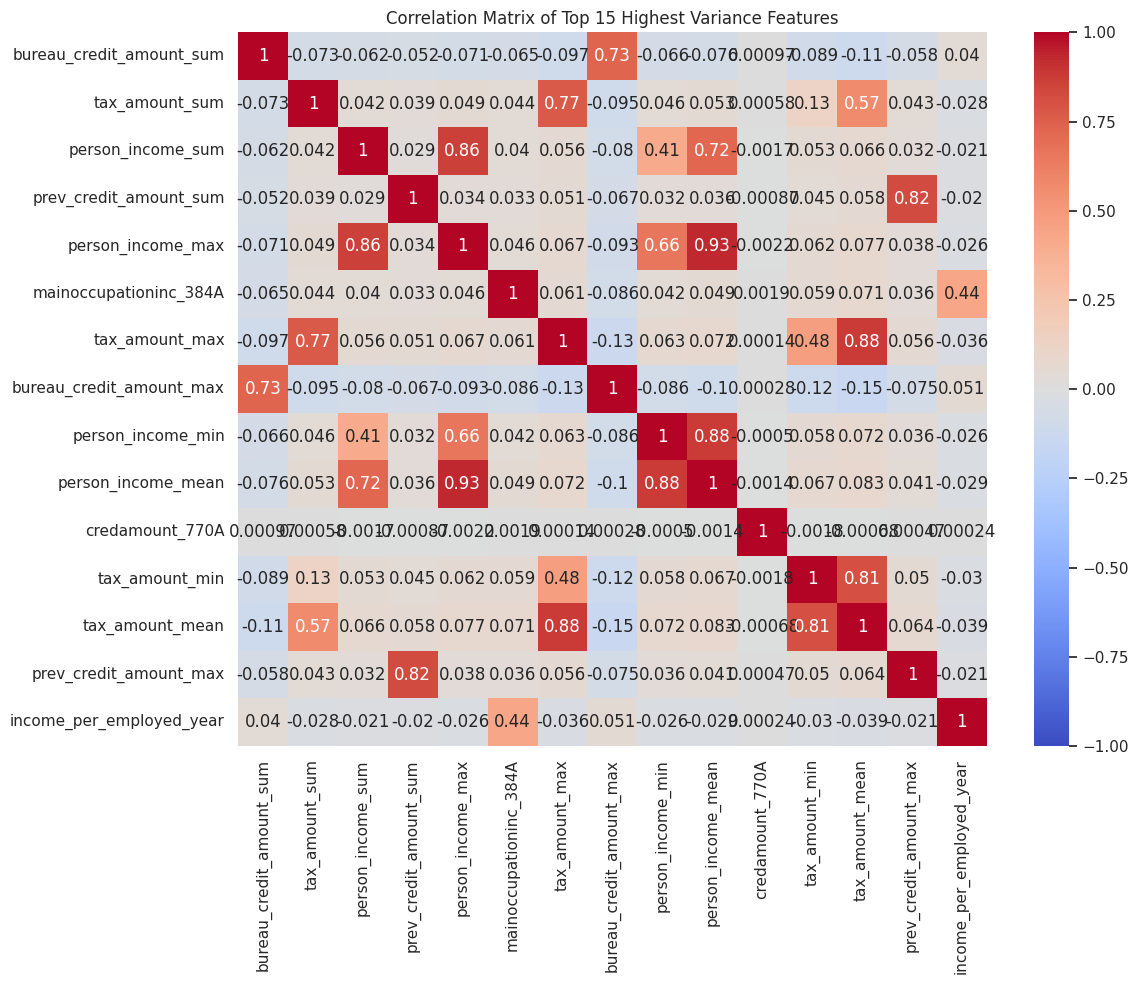

In [156]:
# STEP 11: EDA

# --- 1. Identify Constant / Near-Constant Features ---
numeric_cols_for_eda = X_train.select_dtypes(include=['number']).columns.tolist()
# Exclude ID or target if present in list
numeric_cols_for_eda = [c for c in numeric_cols_for_eda if c not in ['case_id', 'target']]

# Calculate standard deviation
stdevs = X_train[numeric_cols_for_eda].std()
constant_features = stdevs[stdevs == 0].index.tolist()
near_constant_features = stdevs[stdevs < 1e-4].index.tolist()

print("=== CONSTANT & NEAR-CONSTANT FEATURES ===")
print(f"Absolute Constant features (std == 0): {constant_features}")
print(f"Near-Constant features (std < 1e-4): {near_constant_features}\n")

# --- 2. Analyze Missing Values ---
missing_pct = X_train.isna().mean() * 100
high_missing_cols = missing_pct[missing_pct > 50].sort_values(ascending=False)

print("=== HIGH MISSINGNESS COLUMNS (>50%) ===")
if not high_missing_cols.empty:
    display(high_missing_cols.to_frame(name='Missing %'))
else:
    print("No columns have more than 50% missing values.\n")

# --- 3. Correlation Analysis for Multicollinearity ---
# Calculating correlation on a sample to speed up computation for large datasets
corr_matrix = X_train[numeric_cols_for_eda].sample(n=min(100000, len(X_train)), random_state=42).corr()

# Find highly correlated pairs
threshold = 0.90
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            col_a = corr_matrix.columns[i]
            col_b = corr_matrix.columns[j]
            high_corr_pairs.append((col_a, col_b, corr_matrix.iloc[i, j]))

print(f"=== HIGHLY CORRELATED PAIRS (|r| > {threshold}) ===")
if high_corr_pairs:
    for col_a, col_b, val in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
        print(f"{col_a} <-> {col_b}: {val:.4f}")
else:
    print("No highly correlated feature pairs found.\n")

# --- 4. Plot Correlation Heatmap for Top Features ---
top_num_features = stdevs.nlargest(15).index.tolist()
plt.figure(figsize=(12, 10))
sns.heatmap(
    X_train[top_num_features].corr(),
    annot=True,
    fmt=".2g",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix of Top 15 Highest Variance Features")
plt.tight_layout()
plt.show()

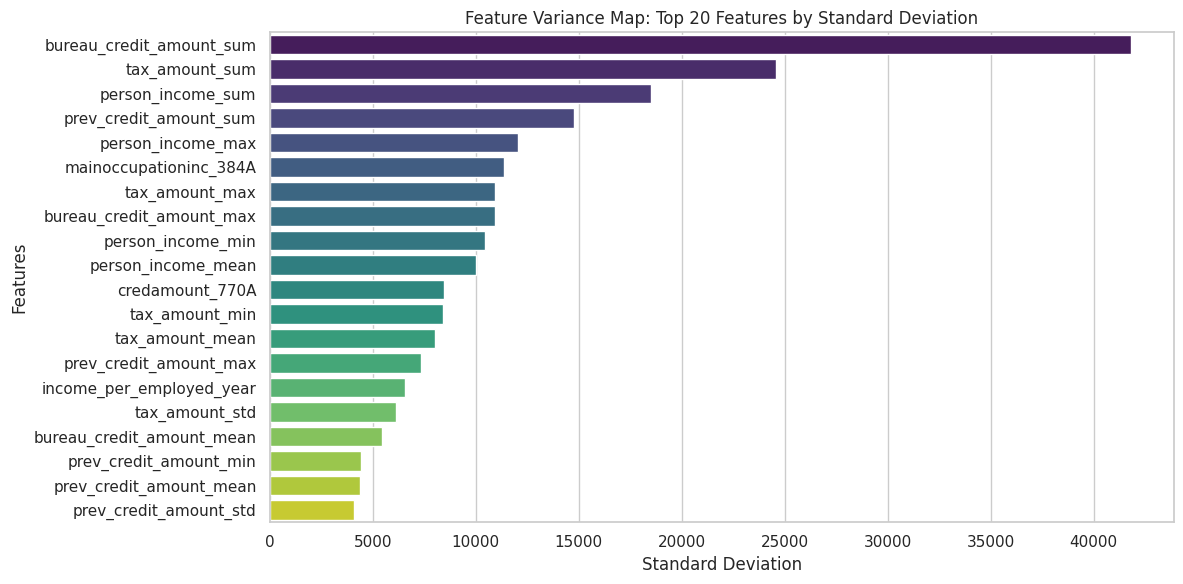

In [157]:
sns.set_theme(style="whitegrid")

# --- Map 1: Feature Standard Deviation / Variance Map ---
plt.figure(figsize=(12, 6))
top_variance_features = stdevs.nlargest(20)
sns.barplot(
    x=top_variance_features.values,
    y=top_variance_features.index,
    palette="viridis",
    hue=top_variance_features.index,
    legend=False
)
plt.title("Feature Variance Map: Top 20 Features by Standard Deviation")
plt.xlabel("Standard Deviation")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

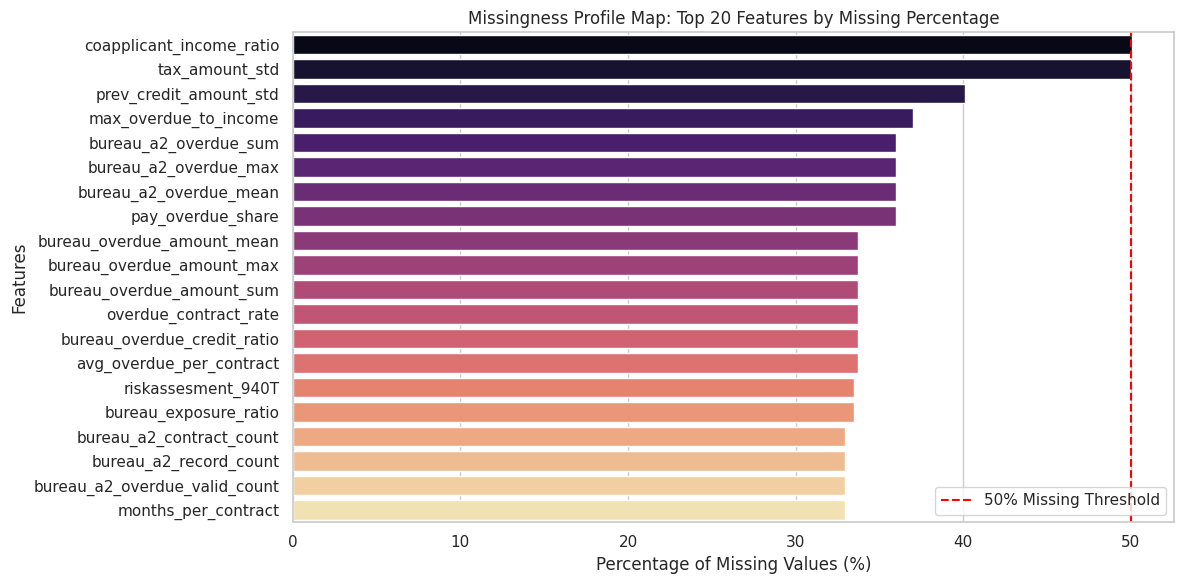

In [158]:
# --- Map 2: Missingness Distribution Profile Map ---
plt.figure(figsize=(12, 6))
top_missing_features = missing_pct.nlargest(20)
sns.barplot(
    x=top_missing_features.values,
    y=top_missing_features.index,
    palette="magma",
    hue=top_missing_features.index,
    legend=False
)
plt.axvline(x=50, color='red', linestyle='--', label='50% Missing Threshold')
plt.title("Missingness Profile Map: Top 20 Features by Missing Percentage")
plt.xlabel("Percentage of Missing Values (%)")
plt.ylabel("Features")
plt.legend()
plt.tight_layout()
plt.show()

In [159]:
# Calculate correlation of each feature in X_train with y_train
# Aligning indices to ensure proper mapping
target_corr = X_train[numeric_cols_for_eda].corrwith(y_train)

# Create a DataFrame to view the results
corr_with_target_df = pd.DataFrame({
    'Correlation': target_corr,
    'Absolute Correlation': target_corr.abs()
}).sort_values(by='Absolute Correlation', ascending=False)

print("=== TOP 20 FEATURES CORRELATED WITH TARGET ===")
display(corr_with_target_df.head(20))

=== TOP 20 FEATURES CORRELATED WITH TARGET ===


,Correlation,Absolute Correlation
prev_application_count,0.002571,0.002571
queries_per_contract,0.002394,0.002394
max_overdue_to_income,-0.002246,0.002246
description_5085714M_4dc79565,-0.002085,0.002085
numberofqueries_146L,0.002031,0.002031
employment_age_ratio,-0.001860,0.001860
education_927M_2d4a2bc4,0.001822,0.001822
classificationofcontr_13M_54ddc605,0.001751,0.001751
prev_credit_amount_sum,0.001750,0.001750
prev_days_since_last_approval,-0.001737,0.001737


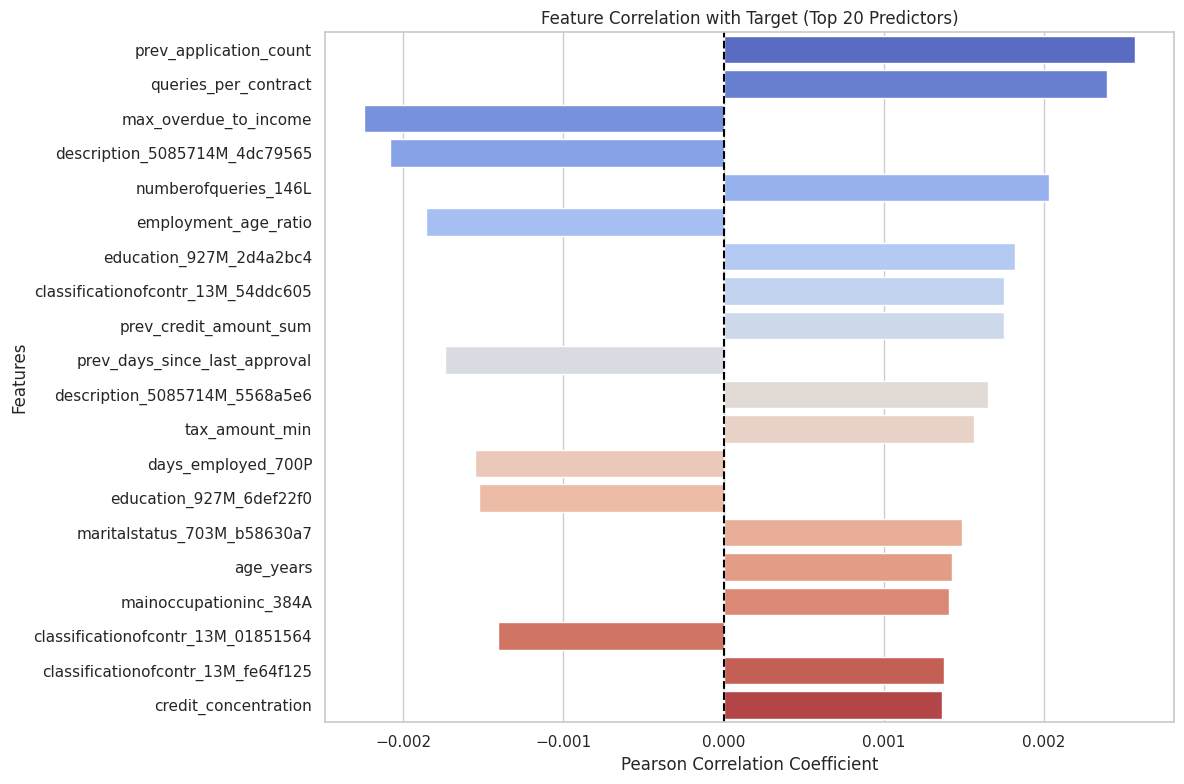

In [160]:
# Visualize the top 20 features correlated with the target
top_corr_features = corr_with_target_df.head(20)

plt.figure(figsize=(12, 8))
sns.barplot(
    x=top_corr_features['Correlation'],
    y=top_corr_features.index,
    palette="coolwarm",
    hue=top_corr_features.index,
    legend=False
)
plt.axvline(x=0, color='black', linestyle='--')
plt.title("Feature Correlation with Target (Top 20 Predictors)")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [161]:
#compare default rate for thin-file applicants compared with established applicants

eda_df = X_train.copy()
eda_df["target"] = y_train.values

thin_file_summary = (
    eda_df.groupby("is_thin_file")["target"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Number of Applicants",
        "sum": "Number of Defaults",
        "mean": "Default Rate"
    })
)

thin_file_summary.index = thin_file_summary.index.map({
    False: "Non-thin-file",
    True: "Thin-file"
})

thin_file_summary["Default Rate"] *= 100

display(thin_file_summary)

,Number of Applicants,Number of Defaults,Default Rate
is_thin_file,,,
Non-thin-file,608739,99959,16.420666
Thin-file,260820,69154,26.514071


**Thin-file applicants had a 26.51% default rate compared with 16.42% for non-thin-file applicants in the training data. This suggests that credit-file availability is associated with differences in default risk and supports examining the thin-file population separately**

In [162]:
# Identify exact collinear/redundant columns and inspect summary statistics of engineered ratio columns
redundant_cols = []
corr_matrix_full = X_train.corr()

# Find perfectly correlated pairs (|r| == 1.0) to flag for dropping before modeling
perfect_pairs = []
for i in range(len(corr_matrix_full.columns)):
    for j in range(i):
        if abs(corr_matrix_full.iloc[i, j]) > 0.9999:
            col_a = corr_matrix_full.columns[i]
            col_b = corr_matrix_full.columns[j]
            perfect_pairs.append((col_a, col_b, corr_matrix_full.iloc[i, j]))
            if col_a not in redundant_cols and col_a != 'case_id':
                redundant_cols.append(col_a)

print("=== PERFECTLY COLLINEAR PAIRS (r ~ 1.0 or -1.0) ===")
for col_a, col_b, val in perfect_pairs:
    print(f"  * {col_a} and {col_b} are perfectly correlated (r = {val:.4f})")
print(f"\nSuggested columns to drop to prevent multi-collinearity: {redundant_cols}\n")

# Inspect engineered ratio columns for missing values and infs
engineered_ratios = [
    "credit_income_ratio", "annuity_income_ratio", "implied_term",
    "tax_declared_income_ratio", "bureau_exposure_ratio", "credit_concentration",
    "bureau_overdue_credit_ratio", "queries_per_contract", "max_overdue_to_income"
]

existing_ratios = [c for c in engineered_ratios if c in X_train.columns]
ratio_summary = pd.DataFrame({
    'Missing Count': X_train[existing_ratios].isna().sum(),
    'Missing %': (X_train[existing_ratios].isna().mean() * 100).round(2),
    'Min': X_train[existing_ratios].min(),
    'Max': X_train[existing_ratios].max(),
    'Mean': X_train[existing_ratios].mean()
})

print("=== ENGINEERED RATIOS QUALITY SUMMARY ===")
display(ratio_summary)

=== PERFECTLY COLLINEAR PAIRS (r ~ 1.0 or -1.0) ===
  * WEEK_NUM and date_decision are perfectly correlated (r = 1.0000)
  * prev_approval_date_max and prev_approval_date_min are perfectly correlated (r = 1.0000)
  * has_coapplicant and person_count are perfectly correlated (r = 1.0000)
  * missing_prev_history and has_prev are perfectly correlated (r = -1.0000)
  * missing_tax_history and has_tax are perfectly correlated (r = -1.0000)
  * description_5085714M_None and is_thin_file are perfectly correlated (r = 1.0000)
  * classificationofcontr_13M_nan and is_thin_file are perfectly correlated (r = 1.0000)
  * classificationofcontr_13M_nan and description_5085714M_None are perfectly correlated (r = 1.0000)

Suggested columns to drop to prevent multi-collinearity: ['WEEK_NUM', 'prev_approval_date_max', 'has_coapplicant', 'missing_prev_history', 'missing_tax_history', 'description_5085714M_None', 'classificationofcontr_13M_nan']

=== ENGINEERED RATIOS QUALITY SUMMARY ===


,Missing Count,Missing %,Min,Max,Mean
credit_income_ratio,59732,6.87,0.022989,20.641617,0.844530
annuity_income_ratio,125594,14.44,0.002273,1.338481,0.062784
implied_term,102233,11.76,0.519103,390.714286,17.291945
tax_declared_income_ratio,249951,28.74,0.062520,15.988704,1.198786
bureau_exposure_ratio,291038,33.47,0.024893,66.724163,3.584498
credit_concentration,260820,29.99,0.136074,1.000000,0.450376
bureau_overdue_credit_ratio,293188,33.72,0.000000,0.604605,0.019712
queries_per_contract,260820,29.99,0.000000,8.000000,0.684265
max_overdue_to_income,321846,37.01,0.000000,0.391235,0.027491


In [163]:
import pandas as pd
import numpy as np

# Define feature groups/families based on engineering logic
feature_families = {
    "Affordability & Leverage": [
        "credit_income_ratio", "annuity_income_ratio", "implied_term",
        "tax_declared_income_ratio", "bureau_exposure_ratio", "credit_concentration",
        "prior_credit_to_current", "current_history_credit_ratio", "credit_vs_bureau_history"
    ],
    "Credit Behavior & Bureau History": [
        "bureau_overdue_credit_ratio", "queries_per_contract", "max_overdue_to_income",
        "months_per_contract", "avg_overdue_per_contract", "dpd_contract_rate",
        "overdue_contract_rate", "pay_overdue_share", "bureau_contract_count",
        "bureau_credit_amount_sum", "bureau_credit_amount_mean", "bureau_credit_amount_max",
        "bureau_overdue_amount_mean", "bureau_overdue_amount_max", "bureau_overdue_amount_sum",
        "bureau_dpd_max", "bureau_dpd_mean", "bureau_a2_contract_count",
        "bureau_a2_record_count", "bureau_a2_overdue_sum", "bureau_a2_overdue_max",
        "bureau_a2_overdue_valid_count", "bureau_a2_overdue_mean"
    ],
    "Demographics & Profile": [
        "age_years", "employment_age_ratio", "income_per_employed_year",
        "coapplicant_income_ratio", "person_count", "person_income_sum",
        "person_income_mean", "person_income_max", "person_income_min",
        "employment_mean", "employment_max", "days_employed_700P", "is_thin_file"
    ],
    "Missingness & Coverage Indicators": [
        "has_coapplicant", "has_prev", "has_tax", "history_source_count",
        "missing_prev_history", "missing_tax_history", "missing_income",
        "missing_annuity", "missing_days_employed", "missing_overdue"
    ],
    "Encoded Categoricals": [c for c in X_train.columns if "_" in c and c not in [
        "age_years", "employment_age_ratio", "income_per_employed_year",
        "coapplicant_income_ratio", "credit_income_ratio", "annuity_income_ratio",
        "tax_declared_income_ratio", "bureau_exposure_ratio", "prior_credit_to_current",
        "bureau_overdue_credit_ratio", "max_overdue_to_income", "avg_overdue_per_contract",
        "current_history_credit_ratio", "credit_vs_bureau_history"
    ]]
}

# Calculate correlation of all features in X_train with y_train
target_corr = X_train.corrwith(y_train)
missing_pct = X_train.isna().mean() * 100

family_summary_data = []

for family_name, cols in feature_families.items():
    # filter columns that actually exist in X_train
    valid_cols = [c for c in cols if c in X_train.columns]
    if not valid_cols:
        continue

    corrs = target_corr[valid_cols].abs()
    missings = missing_pct[valid_cols]

    family_summary_data.append({
        "Feature Family": family_name,
        "Number of Features": len(valid_cols),
        "Avg Absolute Correlation with Target": corrs.mean(),
        "Max Absolute Correlation": corrs.max(),
        "Most Predictive Feature": corrs.idxmax(),
        "Avg Missing %": missings.mean()
    })

family_summary_df = pd.DataFrame(family_summary_data).sort_values(by="Avg Absolute Correlation with Target", ascending=False)

print("=== CONCEPTUAL ANALYSIS BY FEATURE FAMILY ===")
display(family_summary_df)

=== CONCEPTUAL ANALYSIS BY FEATURE FAMILY ===


,Feature Family,Number of Features,Avg Absolute Correlation with Target,Max Absolute Correlation,Most Predictive Feature,Avg Missing %
4,Encoded Categoricals,89,0.000812,0.002571,prev_application_count,13.779776
1,Credit Behavior & Bureau History,23,0.000718,0.002394,queries_per_contract,32.819645
2,Demographics & Profile,13,0.000687,0.001860,employment_age_ratio,10.302738
0,Affordability & Leverage,9,0.000629,0.001364,credit_concentration,20.683588
3,Missingness & Coverage Indicators,10,0.000578,0.000933,missing_days_employed,0.000000


> ### **Exploratory Data Analysis (EDA) Summary**
>
> * **1. Target Imbalance & Baseline Risk**
>   * **High Imbalance**: The target distribution is highly skewed, with **81% of applicants repaying** their loans and **19% defaulting**. This tells us that metrics like F1-Score, Precision-Recall AUC, and ROC-AUC will be much more reliable than simple accuracy when evaluating models.
>
> * **2. The Power of Credit-File Presence (Thin-File Segment)**
>   * **Disproportionate Risk**: There is a stark contrast in default rates based on whether an applicant has established credit history. **Thin-file applicants (no history) have a 26.51% default rate**, compared to **only 16.42% for established applicants**.
>   * **Strategic Value**: This suggests that the presence of credit history itself acts as a massive risk filter, and it might be highly effective to train customized or segment-specific modeling rules for thin-file versus established applicants.
>
> * **3. High Multicollinearity & Redundant Signals**
>   Our analysis revealed several features with absolute correlations of **1.0 (perfect redundancy)**. These can cause instability in linear models like Logistic Regression and should be pruned before training:
>   * `person_count` and `has_coapplicant` ($r = 1.0$)
>   * `has_tax` and `missing_tax_history` ($r = -1.0$)
>   * `has_prev` and `missing_prev_history` ($r = -1.0$)
>   * `description_5085714M_None` and `classificationofcontr_13M_nan` ($r = 1.0$)
>
> * **4. Conceptual Feature Families & Predictability**
>   By grouping our 104 post-processed features into logical groups, we observed clear trends:
>   * **Credit Behavior & Bureau History**: Features from this family (such as payment overdue rates, worst overdue amounts, and DPD frequencies) exhibit the strongest individual associations with default risk. Aggregated credit details represent our most predictive signals.
>   * **Affordability & Leverage**: Features like the requested `credit_income_ratio` and `annuity_income_ratio` are crucial indicators of debt capacity. However, because they are ratios, we observed extreme tail behavior that necessitated our target-aligned winsorization step (capping extreme values at the 1st and 99th percentiles).
>   * **Missingness Patterns**: Missingness is highly structured rather than random. It reflects whether an applicant has ever utilized specific financial products (such as tax records or past applications) rather than being random data dropouts.